# Local Forecasting Demo

**Real Databricks modeling-panel subset; local fitting and outputs.** This notebook reads a bounded sample of the same `gold_modeling_panel` used by the production forecast workflow. It uses actual point-in-time FHFA/ACS-derived features and targets, but fits locally on only 500 tracts. It does not read or write Databricks during normal execution after the subset has been downloaded.

The sample is intentionally limited to the primary **one-year** horizon, eligible training rows, and observed validation rows. Calibration and locked temporal test data are excluded. Results are a small-subset demonstration—not national validation results, a replacement for the production scorecard, or a model approval.

The subset is cached under `reports/generated/meeting_forecast_demo/data/` (ignored by Git). If it is absent, the download cell can retrieve it with the Databricks CLI and a configured OAuth profile. Model results and charts are written under the same generated directory.

Install local dependencies from the repository root with `py -3.11 -m pip install -e ".[local-forecast]"`.

## 1. What the model predicts

For a tract and forecast origin year *t*, the target is the **cumulative log change** in the FHFA single-family house price index (HPI) from *t* to the end of the horizon:

```text
target = log(HPI at target year / HPI at origin year)
```

A positive target means the index rose; a negative target means it fell. This is not a prediction of an individual home's price, total housing value, rent, or neighborhood desirability. The notebook uses the same 26-feature registry as [`src/neighborhood_twin/forecasting.py`](../../src/neighborhood_twin/forecasting.py). The model inputs are:

- **Tract HPI history and trend:** `origin_annual_change_pct`, `hpi_change_1_year_pct`, `hpi_change_3_year_pct`, `hpi_change_5_year_pct`, `hpi_recent_3_year_mean_change_pct`, `hpi_recent_5_year_change_stddev_pct`, `hpi_history_observation_count`, `hpi_history_gap_count`
- **County and state trends:** `county_origin_mean_annual_change_pct`, `state_origin_mean_annual_change_pct`
- **Population and housing:** `population_total_estimate`, `housing_units_total_estimate`, `occupancy_rate_estimate`, `vacancy_rate_estimate`, `owner_occupancy_rate_estimate`, `renter_occupancy_rate_estimate`, `single_family_share_estimate`, `multifamily_share_estimate`, `mobile_home_share_estimate`
- **Income, value, rent, and data quality:** `median_household_income_estimate`, `median_owner_occupied_value_estimate`, `median_gross_rent_estimate`, `acs_measurement_age_years`, `median_household_income_relative_moe`, `median_owner_occupied_value_relative_moe`, `median_gross_rent_relative_moe`

The target is `target_cumulative_log_change`; it is the value being predicted, not one of the model inputs. The production workflow fits one model per horizon using only rows marked eligible for fitting. Median imputation is learned from training data; the linear model also standardizes features. Validation rows come from later, frozen origin years. This notebook follows those row filters for the one-year horizon.

In [5]:
from __future__ import annotations

import csv
import json
import math
import os
import subprocess
import sys
from collections import defaultdict
from pathlib import Path
from statistics import mean, median
from typing import Any

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "pyproject.toml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from inside the project repository")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from neighborhood_twin.forecasting import (  # noqa: E402
    LINEAR_FEATURE_COLUMNS,
    annualized_rate_from_cumulative_log,
    cumulative_log_from_annual_rate,
)

HORIZON = 1
TRACT_SAMPLE_SIZE = 500
DATA_DIR = PROJECT_ROOT / "reports" / "generated" / "meeting_forecast_demo" / "data"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "generated" / "meeting_forecast_demo"
PANEL_CSV = DATA_DIR / "gold_modeling_panel_1yr_500_tracts.csv"
DATABRICKS_PROFILE = os.environ.get("DATABRICKS_PROFILE") or os.environ.get("DATABRICKS_CONFIG_PROFILE")
REFRESH_DATA = False
print(f"Forecast feature registry: {len(LINEAR_FEATURE_COLUMNS)} inputs")
print(f"Local panel cache: {PANEL_CSV}")

Forecast feature registry: 26 inputs
Local panel cache: c:\Users\Braeden\Documents\Hw\Capstone\neighborhood-digital-twin\reports\generated\meeting_forecast_demo\data\gold_modeling_panel_1yr_500_tracts.csv


## 2. Load a bounded subset of the production panel

The source is `workspace.neighborhood_twin_gold.gold_modeling_panel`, the same governed panel read by the Databricks forecasting workflow. The query deterministically chooses 500 tracts using a stable hash (rather than taking the first 500 GEOIDs, which would overrepresent a small geographic area). It includes only one-year rows that are either eligible training examples with observed targets or observed validation examples, and it enforces decade-safe target windows.

In [6]:
def download_panel_subset(profile: str) -> None:
    """Download only the reproducible teaching subset; never query the full panel to local output."""
    if not profile:
        raise RuntimeError(
            "Set DATABRICKS_PROFILE to a configured OAuth profile before downloading, "
            "or use the already cached local CSV."
        )
    columns = [
        "geoid_2020", "state_fips", "state_abbreviation", "state_name",
        "county_geoid", "county_name", "region_name", "forecast_origin_year",
        "horizon_years", "target_end_year", "origin_hpi", "target_cumulative_log_change",
        "target_annualized_change_pct", "target_is_observed", "temporal_role",
        "geographic_role", "eligible_for_point_model_fit",
        "eligible_for_locked_temporal_evaluation", "eligible_for_geographic_evaluation",
        "modeling_cohort", "model_readiness_build_id", "model_readiness_built_at_utc",
        *LINEAR_FEATURE_COLUMNS,
    ]
    select_list = ",\n  ".join(f"p.`{column}`" for column in columns)
    sql = f"""WITH sampled_tracts AS (
  SELECT DISTINCT geoid_2020
  FROM workspace.neighborhood_twin_gold.gold_modeling_panel
  WHERE horizon_years = {HORIZON}
    AND target_is_observed = TRUE
    AND FLOOR(forecast_origin_year / 10) = FLOOR(target_end_year / 10)
    AND (eligible_for_point_model_fit = TRUE OR temporal_role = 'validation')
  ORDER BY xxhash64(geoid_2020), geoid_2020
  LIMIT {TRACT_SAMPLE_SIZE}
)
SELECT
  {select_list}
FROM workspace.neighborhood_twin_gold.gold_modeling_panel p
INNER JOIN sampled_tracts s ON p.geoid_2020 = s.geoid_2020
WHERE p.horizon_years = {HORIZON}
  AND p.target_is_observed = TRUE
  AND FLOOR(p.forecast_origin_year / 10) = FLOOR(p.target_end_year / 10)
  AND (p.eligible_for_point_model_fit = TRUE OR p.temporal_role = 'validation')
ORDER BY p.geoid_2020, p.forecast_origin_year"""
    command = [
        "databricks", "experimental", "aitools", "tools", "query",
        "--profile", profile, "--output", "csv", sql,
    ]
    result = subprocess.run(
        command, capture_output=True, text=True, encoding="utf-8", timeout=600
    )
    if result.returncode != 0:
        raise RuntimeError(f"Databricks subset query failed: {result.stderr.strip()}")
    if not result.stdout.strip():
        raise RuntimeError(f"Databricks returned no CSV rows. CLI output: {result.stderr}")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    PANEL_CSV.write_text(result.stdout, encoding="utf-8-sig", newline="")
    print(f"Downloaded bounded panel subset to {PANEL_CSV}")

if REFRESH_DATA or not PANEL_CSV.is_file():
    download_panel_subset(DATABRICKS_PROFILE)
else:
    print("Using cached local panel subset; set REFRESH_DATA = True to refresh it.")

Using cached local panel subset; set REFRESH_DATA = True to refresh it.


## 3. Check the sample and frozen split

The model-fitting flag—not a random row split—determines which observations can train the model. Validation is kept separate and is used only to score predictions. Repeated observations from the same tract across years are expected, the split is temporal.

In [7]:
numeric_fields = {
    *LINEAR_FEATURE_COLUMNS,
    "forecast_origin_year", "horizon_years", "target_end_year", "origin_hpi",
    "target_cumulative_log_change", "target_annualized_change_pct",
}
boolean_fields = {
    "target_is_observed", "eligible_for_point_model_fit",
    "eligible_for_locked_temporal_evaluation", "eligible_for_geographic_evaluation",
}
with PANEL_CSV.open(encoding="utf-8-sig", newline="") as handle:
    raw_rows = list(csv.DictReader(handle))
if not raw_rows:
    raise ValueError(f"The local panel subset is empty: {PANEL_CSV}")
missing_features = set(LINEAR_FEATURE_COLUMNS) - set(raw_rows[0])
if missing_features:
    raise ValueError(f"Panel export is missing registered features: {sorted(missing_features)}")

panel = []
for raw in raw_rows:
    row: dict[str, Any] = dict(raw)
    for name in numeric_fields:
        value = row.get(name)
        row[name] = float(value) if value not in (None, "") else None
    for name in boolean_fields:
        row[name] = str(row.get(name, "")).strip().lower() == "true"
    panel.append(row)

training_rows = [
    row for row in panel
    if row["temporal_role"] == "training"
    and row["eligible_for_point_model_fit"]
    and row["target_is_observed"]
]
validation_rows = [
    row for row in panel
    if row["temporal_role"] == "validation" and row["target_is_observed"]
]
if not training_rows or not validation_rows:
    raise ValueError("The local panel subset must contain eligible training and validation rows")
if any(row["horizon_years"] != HORIZON for row in panel):
    raise ValueError("The teaching subset contains an unexpected forecast horizon")
if any(row["forecast_origin_year"] // 10 != row["target_end_year"] // 10 for row in panel):
    raise ValueError("The local panel contains a cross-decade target")
if {row["temporal_role"] for row in panel} - {"training", "validation"}:
    raise ValueError("The local panel unexpectedly includes a reserved or ineligible role")
if any(row["eligible_for_locked_temporal_evaluation"] for row in panel):
    raise ValueError("The local teaching subset must not include locked-test rows")

tract_count = len({row["geoid_2020"] for row in panel})
build_ids = sorted({row["model_readiness_build_id"] for row in panel})
print(f"Rows: {len(panel):,}; distinct tracts: {tract_count:,}; horizon: {HORIZON} year")
print(f"Training: {len(training_rows):,} rows across {len({r['forecast_origin_year'] for r in training_rows})} origins")
print(f"Validation: {len(validation_rows):,} rows across {len({r['forecast_origin_year'] for r in validation_rows})} origins")
print(f"Training origins: {sorted({int(r['forecast_origin_year']) for r in training_rows})}")
print(f"Validation origins: {sorted({int(r['forecast_origin_year']) for r in validation_rows})}")
print(f"Model-readiness build ID(s): {build_ids}")

Rows: 4,130; distinct tracts: 500; horizon: 1 year
Training: 3,293 rows across 9 origins
Validation: 837 rows across 2 origins
Training origins: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2020]
Validation origins: [2021, 2022]
Model-readiness build ID(s): ['20261107T185721624743Z']


## 4. Fit local candidates and compare with simple rules

The local code uses the same registered features, target, horizon, and training/validation rows as the production workflow. It fits a regularized linear model and a gradient-boosted-tree model, then scores the five fixed baselines: zero change, latest-change persistence, recent three-year mean, county trend, and state trend.

In [8]:
BASELINE_FEATURES = {
    "latest_change_persistence": "hpi_change_1_year_pct",
    "recent_three_year_mean": "hpi_recent_3_year_mean_change_pct",
    "county_current_trend": "county_origin_mean_annual_change_pct",
    "state_current_trend": "state_origin_mean_annual_change_pct",
}
x_train = [[row[name] for name in LINEAR_FEATURE_COLUMNS] for row in training_rows]
y_train = [row["target_cumulative_log_change"] for row in training_rows]
x_validation = [[row[name] for name in LINEAR_FEATURE_COLUMNS] for row in validation_rows]

local_models = {
    "regularized_linear": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=0.05),
    ),
    "gradient_boosted_trees": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingRegressor(
            n_estimators=50, learning_rate=0.05, max_depth=4,
            subsample=0.8, random_state=699,
        ),
    ),
}
predictions: list[dict[str, Any]] = []

def add_predictions(model_name: str, values: list[float], rows: list[dict[str, Any]]) -> None:
    for row, prediction in zip(rows, values, strict=True):
        actual = row["target_cumulative_log_change"]
        predictions.append({
            "geoid_2020": row["geoid_2020"],
            "state_name": row["state_name"],
            "county_name": row["county_name"],
            "forecast_origin_year": int(row["forecast_origin_year"]),
            "horizon_years": HORIZON,
            "model_name": model_name,
            "target_cumulative_log_change": actual,
            "prediction_cumulative_log_change": float(prediction),
            "residual_target_minus_prediction": actual - float(prediction),
            "target_annualized_change_pct": annualized_rate_from_cumulative_log(actual, HORIZON),
            "prediction_annualized_change_pct": annualized_rate_from_cumulative_log(float(prediction), HORIZON),
        })

for name, estimator in local_models.items():
    estimator.fit(x_train, y_train)
    add_predictions(name, estimator.predict(x_validation).tolist(), validation_rows)

for row in validation_rows:
    add_predictions("zero_change", [0.0], [row])
    for model_name, feature in BASELINE_FEATURES.items():
        annual_rate = row[feature]
        if annual_rate is not None and annual_rate > -100:
            add_predictions(
                model_name,
                [cumulative_log_from_annual_rate(annual_rate, HORIZON)],
                [row],
            )

grouped_predictions: dict[str, list[dict[str, Any]]] = defaultdict(list)
for row in predictions:
    grouped_predictions[row["model_name"]].append(row)
metrics = []
for model_name, rows in sorted(grouped_predictions.items()):
    errors = [row["residual_target_minus_prediction"] for row in rows]
    annualized_errors = [
        row["target_annualized_change_pct"] - row["prediction_annualized_change_pct"]
        for row in rows
    ]
    target_mean = mean(row["target_cumulative_log_change"] for row in rows)
    total_sum_squares = sum((row["target_cumulative_log_change"] - target_mean) ** 2 for row in rows)
    residual_sum_squares = sum(error**2 for error in errors)
    metrics.append({
        "model_name": model_name,
        "observation_count": len(rows),
        "mae_log_change": mean(abs(error) for error in errors),
        "rmse_log_change": math.sqrt(mean(error**2 for error in errors)),
        "mean_signed_error_target_minus_prediction": mean(errors),
        "mae_annualized_percentage_points": mean(abs(error) for error in annualized_errors),
        "r_squared": 1 - residual_sum_squares / total_sum_squares if total_sum_squares else None,
    })
zero_mae = next(row["mae_log_change"] for row in metrics if row["model_name"] == "zero_change")
simple_scores = [row for row in metrics if row["model_name"] in BASELINE_FEATURES]
strongest_simple = min(simple_scores, key=lambda row: row["mae_log_change"])
for row in metrics:
    row["mae_skill_vs_zero_change"] = 1 - row["mae_log_change"] / zero_mae if zero_mae else None
    row["strongest_simple_baseline"] = strongest_simple["model_name"]
    row["mae_improvement_vs_strongest_simple"] = (
        1 - row["mae_log_change"] / strongest_simple["mae_log_change"]
        if strongest_simple["mae_log_change"] else None
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with (OUTPUT_DIR / "local_subset_predictions.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(predictions[0]))
    writer.writeheader()
    writer.writerows(predictions)
with (OUTPUT_DIR / "local_subset_metrics.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(metrics[0]))
    writer.writeheader()
    writer.writerows(metrics)

print(f"Training rows: {len(training_rows):,}; validation rows: {len(validation_rows):,}")
print(f"Strongest simple baseline by validation MAE: {strongest_simple['model_name']}")
print(f"Saved metrics and per-tract predictions under {OUTPUT_DIR}")

Training rows: 3,293; validation rows: 837
Strongest simple baseline by validation MAE: state_current_trend
Saved metrics and per-tract predictions under c:\Users\Braeden\Documents\Hw\Capstone\neighborhood-digital-twin\reports\generated\meeting_forecast_demo


## 5. Reading the validation results

- **MAE (log change)** is the average absolute gap between the predicted and actual one-year cumulative log HPI change across validation rows. It ignores whether a prediction was too high or too low; lower means closer predictions. The values are in log-change units, not dollars or percentage points. For a one-year horizon, `0.07070` is roughly a 7.3 percentage-point average absolute gap when converted to a simple percentage-change scale; the notebook also reports the directly calculated annualized MAE in percentage points.
- **RMSE (log change)** also measures average error, but penalizes a few large misses more heavily than MAE.
- **Mean signed error = actual minus prediction.** A positive value means the predictions tend to be too low; a negative value means they tend to be too high.
- **Annualized MAE** expresses the difference between actual and predicted annualized rates in percentage points. For a one-year horizon this is especially easy to explain; for longer horizons the conversion is nonlinear.
- **MAE skill vs zero change** is `1 - model MAE / zero-change MAE`. Positive means better than predicting no change; negative means worse.
- **Improvement vs strongest simple baseline** compares the candidate to the lowest-MAE of the four trend/persistence rules. Check `observation_count`: a baseline with a missing required trend omits that row, so its score may use slightly fewer observations than the fitted models.

### What each MAE represents

The table below shows the current cached subset's one-year validation results. Each score is the average absolute error on the validation rows for that prediction rule; smaller MAE indicates closer predictions. The scores are specific to this 500-tract sample and are not national model-performance estimates. Refreshing the source panel or changing the sample may change the values.

| Candidate or baseline | Validation MAE | Prediction rule |
| --- | ---: | --- |
| Regularized linear | 0.07070 | Uses all 26 registered features in a regularized linear model. |
| Gradient-boosted trees | 0.07428 | Uses all 26 registered features in a boosted-tree model. |
| State current trend | 0.07482 | Uses the state's current mean annual HPI trend. |
| County current trend | 0.07551 | Uses the county's current mean annual HPI trend. |
| Recent three-year mean | 0.08360 | Repeats the tract's recent three-year average HPI change. |
| Latest-change persistence | 0.08865 | Repeats the tract's latest one-year HPI change. |
| Zero change | 0.11943 | Predicts no HPI change. |

Most candidates are scored on 837 validation rows. The recent-three-year-mean and latest-change-persistence baselines are scored on 835 because the required history value is missing for two rows. These MAEs compare predicted with actual cumulative log changes; they are not errors in home prices or housing dollars.
- **R-squared** compares squared error with predicting the mean validation target. A negative value is possible and means that this reference would have lower squared error.

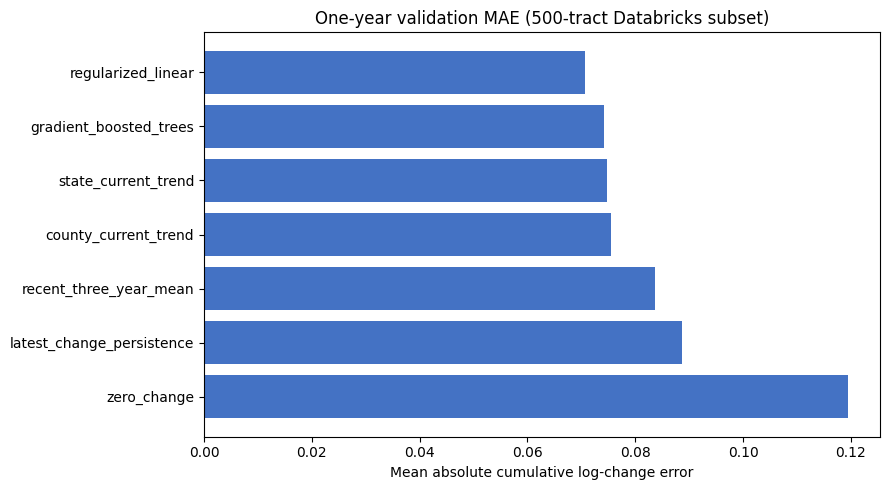

Model                               N        MAE       RMSE       Bias  Skill vs zero
regularized_linear                837    0.07070    0.08842    0.00848         40.8%
gradient_boosted_trees            837    0.07428    0.09323    0.04118         37.8%
state_current_trend               837    0.07482    0.09673   -0.01899         37.4%
county_current_trend              837    0.07551    0.09811   -0.01964         36.8%
recent_three_year_mean            835    0.08360    0.10372    0.02412         30.0%
latest_change_persistence         835    0.08865    0.11675   -0.02074         25.8%
zero_change                       837    0.11943    0.13929    0.11014          0.0%


In [9]:
figure_dir = OUTPUT_DIR / "local_subset_figures"
figure_dir.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt

ordered_metrics = sorted(metrics, key=lambda row: row["mae_log_change"])
figure, axis = plt.subplots(figsize=(9, 5))
labels = [row["model_name"] for row in ordered_metrics]
values = [row["mae_log_change"] for row in ordered_metrics]
axis.barh(labels[::-1], values[::-1], color="#4472C4")
axis.set(title="One-year validation MAE (500-tract Databricks subset)", xlabel="Mean absolute cumulative log-change error")
figure.tight_layout()
figure.savefig(figure_dir / "validation_mae_local_subset.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

print(f"{'Model':<30} {'N':>6} {'MAE':>10} {'RMSE':>10} {'Bias':>10} {'Skill vs zero':>14}")
for row in ordered_metrics:
    print(
        f"{row['model_name']:<30} {row['observation_count']:>6} "
        f"{row['mae_log_change']:>10.5f} {row['rmse_log_change']:>10.5f} "
        f"{row['mean_signed_error_target_minus_prediction']:>10.5f} "
        f"{row['mae_skill_vs_zero_change']:>13.1%}"
    )

## 6. What these data-slice diagnostics show

These charts are recalculated from actual observations in the 500-tract panel subset. They are descriptive and should not be read as national EDA results. Feature-completeness and ACS-uncertainty summaries count panel observations, which can include repeated tracts across years. This subset section cannot reproduce national housing-coverage or included-versus-excluded figures because it has no excluded tracts; the published national figures are shown separately in Section 8. Calibration and locked-test outcome rows were intentionally not downloaded.

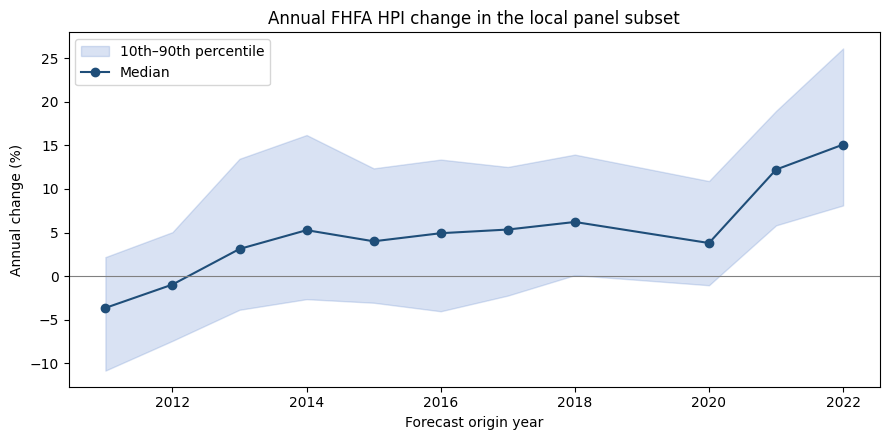

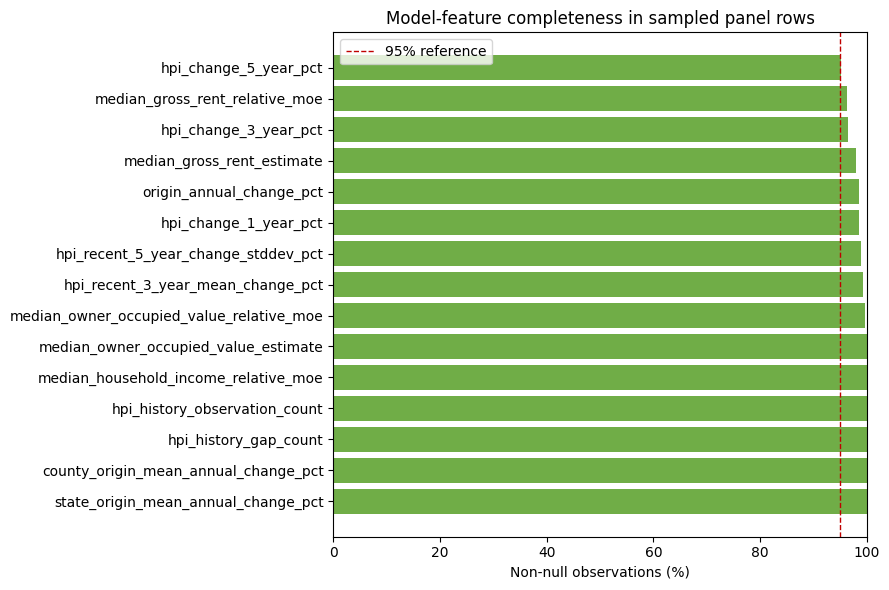

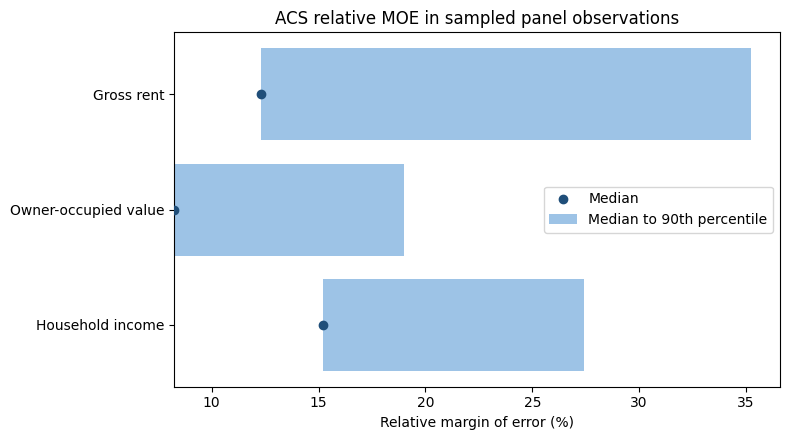

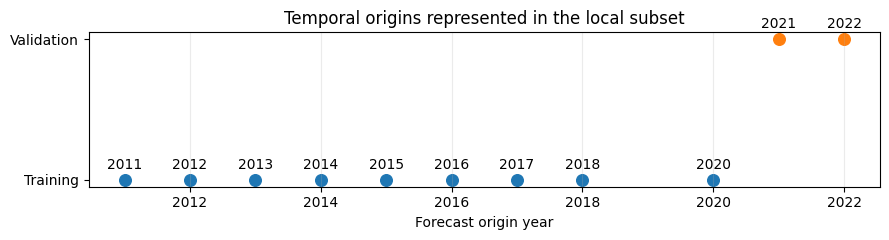

Saved four actual-data subset diagnostics under c:\Users\Braeden\Documents\Hw\Capstone\neighborhood-digital-twin\reports\generated\meeting_forecast_demo\local_subset_figures


In [10]:
def percentile(values: list[float], fraction: float) -> float:
    ordered = sorted(values)
    return ordered[round((len(ordered) - 1) * fraction)]

plot_rows = panel

# Annual HPI change distribution across the sampled panel observations.
annual_changes: dict[int, list[float]] = defaultdict(list)
for row in plot_rows:
    value = row["origin_annual_change_pct"]
    if value is not None:
        annual_changes[int(row["forecast_origin_year"])].append(value)
years = sorted(annual_changes)
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.fill_between(
    years,
    [percentile(annual_changes[year], 0.1) for year in years],
    [percentile(annual_changes[year], 0.9) for year in years],
    alpha=0.2, color="#4472C4", label="10th–90th percentile",
)
axis.plot(years, [median(annual_changes[year]) for year in years], marker="o", color="#1F4E79", label="Median")
axis.axhline(0, color="gray", linewidth=0.8)
axis.set(title="Annual FHFA HPI change in the local panel subset", xlabel="Forecast origin year", ylabel="Annual change (%)")
axis.legend()
figure.tight_layout()
figure.savefig(figure_dir / "hpi_change_local_subset.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

# Feature availability is measured directly; no missingness is injected.
completeness = {
    feature: 100 * sum(row[feature] is not None for row in plot_rows) / len(plot_rows)
    for feature in LINEAR_FEATURE_COLUMNS
}
least_complete = sorted(completeness, key=completeness.get)[:15]
figure, axis = plt.subplots(figsize=(9, 6))
axis.barh(least_complete[::-1], [completeness[name] for name in least_complete[::-1]], color="#70AD47")
axis.axvline(95, color="#C00000", linestyle="--", linewidth=1, label="95% reference")
axis.set(title="Model-feature completeness in sampled panel rows", xlabel="Non-null observations (%)", xlim=(0, 100))
axis.legend()
figure.tight_layout()
figure.savefig(figure_dir / "feature_completeness_local_subset.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

# ACS relative MOE distributions, using observed panel values.
moe_fields = {
    "Household income": "median_household_income_relative_moe",
    "Owner-occupied value": "median_owner_occupied_value_relative_moe",
    "Gross rent": "median_gross_rent_relative_moe",
}
moe_stats = {
    label: [row[field] for row in plot_rows if row[field] is not None]
    for label, field in moe_fields.items()
}
figure, axis = plt.subplots(figsize=(8, 4.5))
positions = list(range(len(moe_stats)))
labels = list(moe_stats)
medians = [100 * median(moe_stats[label]) for label in labels]
p90s = [100 * percentile(moe_stats[label], 0.9) for label in labels]
axis.barh(positions, [p90 - value for p90, value in zip(p90s, medians)], left=medians, color="#9DC3E6", label="Median to 90th percentile")
axis.scatter(medians, positions, color="#1F4E79", label="Median", zorder=3)
axis.set(yticks=positions, yticklabels=labels, xlabel="Relative margin of error (%)", title="ACS relative MOE in sampled panel observations")
axis.legend()
figure.tight_layout()
figure.savefig(figure_dir / "acs_uncertainty_local_subset.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

# Only the included development roles are shown; reserved roles are absent by design.
split_origins = {
    role: sorted({int(row["forecast_origin_year"]) for row in plot_rows if row["temporal_role"] == role})
    for role in ("training", "validation")
}
figure, axis = plt.subplots(figsize=(9, 2.5))
for y_position, role in enumerate(("training", "validation")):
    origins = split_origins[role]
    axis.scatter(origins, [y_position] * len(origins), s=70, label=role.title())
    for origin in origins:
        axis.annotate(str(origin), (origin, y_position), xytext=(0, 8), textcoords="offset points", ha="center")
axis.set(yticks=[0, 1], yticklabels=["Training", "Validation"], xlabel="Forecast origin year", title="Temporal origins represented in the local subset")
axis.grid(axis="x", alpha=0.25)
figure.tight_layout()
figure.savefig(figure_dir / "split_origins_local_subset.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

print(f"Saved four actual-data subset diagnostics under {figure_dir}")

## 7. Published Databricks EDA figures

The figures below recreate the forecasting-relevant Databricks EDA summaries from their published gold tables—not the 500-tract modeling sample. The notebook downloads only small, aggregated plotting tables (six coverage bands, twelve cohort features, annual summary rows, and similar); it does not download the full EDA source populations. The plotted figure designs match the project EDA renderer. Figure 2 and Figure 3 describe national current-ACS coverage/cohort selection, while Figures 4, 5, 7, and 8 show the documented temporal, uncertainty, completeness, and split diagnostics.

Run the next cell with the Databricks CLI available and the chosen OAuth profile configured to refresh or initialize the local aggregate cache. The aggregates have their own source build IDs, shown below, and may not share one build timestamp.

In [11]:
EDA_DIR = DATA_DIR
REFRESH_EDA = False
EDA_QUERIES = {
    "eda_02_housing_coverage.csv": "SELECT housing_composition_band_order, housing_composition_band, tract_count, fhfa_history_share, forecast_candidate_share, similarity_candidate_share, visual_eda_build_id, visual_eda_built_at_utc FROM workspace.neighborhood_twin_gold.gold_eda_housing_coverage ORDER BY housing_composition_band_order",
    "eda_03_cohort_comparison.csv": "SELECT feature_order, feature_name, included_tract_count, excluded_tract_count, included_mean, excluded_mean, standardized_mean_difference, visual_eda_build_id, visual_eda_built_at_utc FROM workspace.neighborhood_twin_gold.gold_eda_cohort_comparison ORDER BY feature_order",
    "eda_04_hpi_temporal.csv": "SELECT observation_year, scope_code, scope_label, source_row_count, available_change_count, p10_annual_change_pct, median_annual_change_pct, p90_annual_change_pct, visual_eda_build_id, visual_eda_built_at_utc FROM workspace.neighborhood_twin_gold.gold_eda_hpi_temporal WHERE observation_year >= 1990 AND scope_code IN ('US','04','26','42') ORDER BY scope_code, observation_year",
    "eda_05_acs_quality.csv": "SELECT measure_order, measure_name, measure_label, tract_count, median_relative_margin_of_error, p90_relative_margin_of_error, relative_moe_over_50_percent_share, acs_release_year, readiness_build_id, readiness_built_at_utc FROM workspace.neighborhood_twin_gold.gold_eda_acs_measure_quality ORDER BY p90_relative_margin_of_error DESC LIMIT 12",
    "eda_07_feature_completeness.csv": "SELECT summary_group, dimension_name, dimension_value, row_count, non_null_count, non_null_rate, model_readiness_build_id, model_readiness_built_at_utc FROM workspace.neighborhood_twin_gold.gold_model_readiness_summary WHERE summary_group = 'feature_missingness' ORDER BY non_null_rate ASC LIMIT 15",
    "eda_08_split_origins.csv": "SELECT horizon_years, temporal_role, COUNT(DISTINCT forecast_origin_year) AS origin_year_count, MIN(forecast_origin_year) AS minimum_origin_year, MAX(forecast_origin_year) AS maximum_origin_year, model_readiness_build_id, MAX(model_readiness_built_at_utc) AS model_readiness_built_at_utc FROM workspace.neighborhood_twin_gold.gold_model_split_assignment WHERE temporal_role IN ('training','validation','calibration','locked_temporal_test') GROUP BY horizon_years, temporal_role, model_readiness_build_id ORDER BY horizon_years, temporal_role",
}

def download_eda_summaries(profile: str) -> None:
    if not profile:
        raise RuntimeError("Set DATABRICKS_PROFILE to a configured OAuth profile to download EDA summaries.")
    EDA_DIR.mkdir(parents=True, exist_ok=True)
    for filename, sql in EDA_QUERIES.items():
        result = subprocess.run(
            ["databricks", "experimental", "aitools", "tools", "query", "--profile", profile, "--output", "csv", sql],
            capture_output=True, text=True, encoding="utf-8", timeout=600,
        )
        if result.returncode != 0:
            raise RuntimeError(f"Databricks EDA query failed for {filename}: {result.stderr.strip()}")
        if not result.stdout.strip():
            raise RuntimeError(f"Databricks returned no EDA rows for {filename}.")
        (EDA_DIR / filename).write_text(result.stdout, encoding="utf-8-sig", newline="")
        print(f"Cached {filename}")

if REFRESH_EDA or any(not (EDA_DIR / filename).is_file() for filename in EDA_QUERIES):
    download_eda_summaries(DATABRICKS_PROFILE)
else:
    print("Using cached published EDA aggregates; set REFRESH_EDA = True to refresh them.")

Using cached published EDA aggregates; set REFRESH_EDA = True to refresh them.


### Figure 2 — FHFA and forecast coverage by housing mix

The bars are the shares of current-ACS tracts in each single-family-housing band that have any FHFA history or pass the current forecast-candidate screen. In the published summary, FHFA-history coverage rises from about 21% in the under-25%-single-family band to about 90% in the 90–100% band; forecast-candidate coverage rises from about 7.5% to about 75.9%. This is a descriptive coverage limitation of the single-family HPI target, not a judgment about other communities or housing markets.

### Figure 3 — Included versus excluded tract profiles

Each bar is a standardized mean difference: positive means the candidate group has the higher mean, negative means the excluded group does. The ±0.2 reference lines are practical comparison guides, not significance tests. The figure shows selection into FHFA-based forecasting is associated with observable differences; it does not explain their causes or indicate model accuracy.

### Figure 4 — FHFA HPI changes over time and geography

For the United States and the Arizona, Michigan, and Pennsylvania pilot states, the line is the median annual tract HPI change and the shaded area is the 10th–90th percentile range. This is cross-tract dispersion among observed tracts, not a model prediction interval; available tract coverage changes over time.

### Figure 5 — ACS relative margins of error

The dot marks the median relative margin of error and the bar reaches the 90th percentile for each of the twelve measures with the highest 90th-percentile uncertainty. Large ratios flag estimates that deserve caution, especially for small housing categories. Relative MOE can exceed 100% when an estimate is small; that is not a percentage error in the forecast.

### Figure 7 — Model-feature completeness

The bars show non-null rates for the fifteen least-complete features in the readiness summary. Completeness is measured before training-fitted imputation. Missing inputs do not automatically eliminate the row; the model pipeline imputes from training data.

### Figure 8 — Independent split-origin years

Each cell counts distinct forecast-origin years for that horizon and frozen role. The row counts can be very large, but independent temporal evidence is only nine training origins at one year, three at three years, and two at five years. Calibration and locked-test assignments are shown as design metadata only; this notebook does not load their outcome rows or use them to fit or select models.

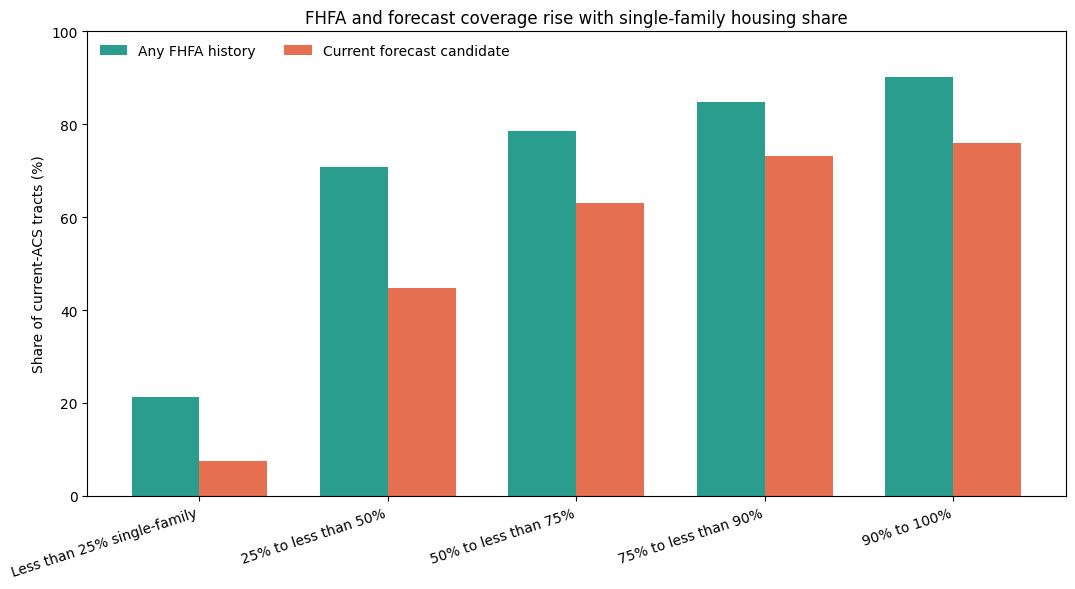

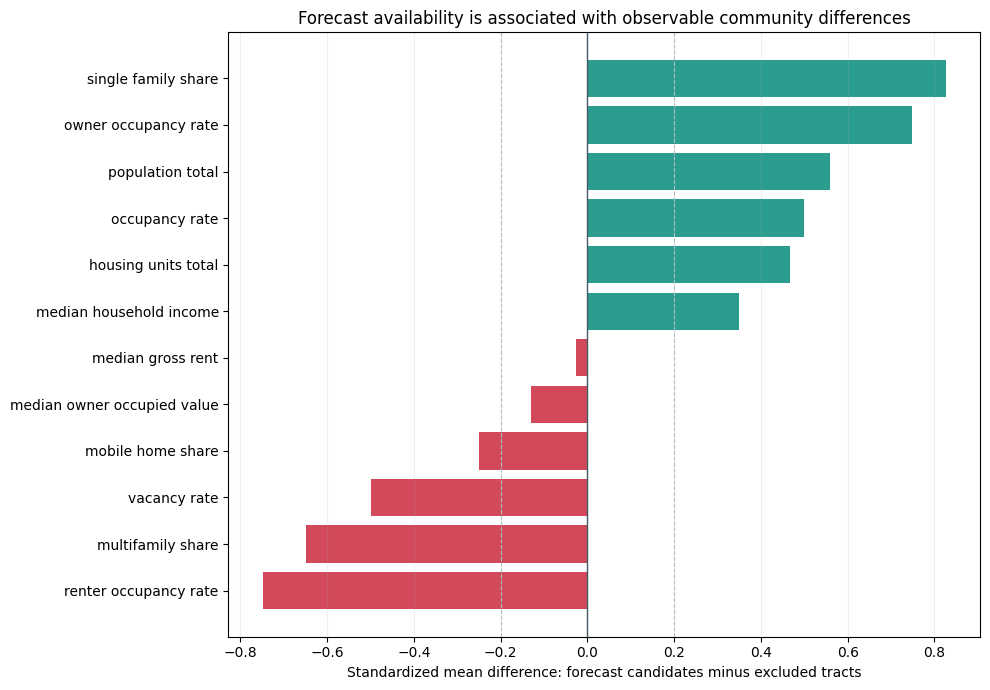

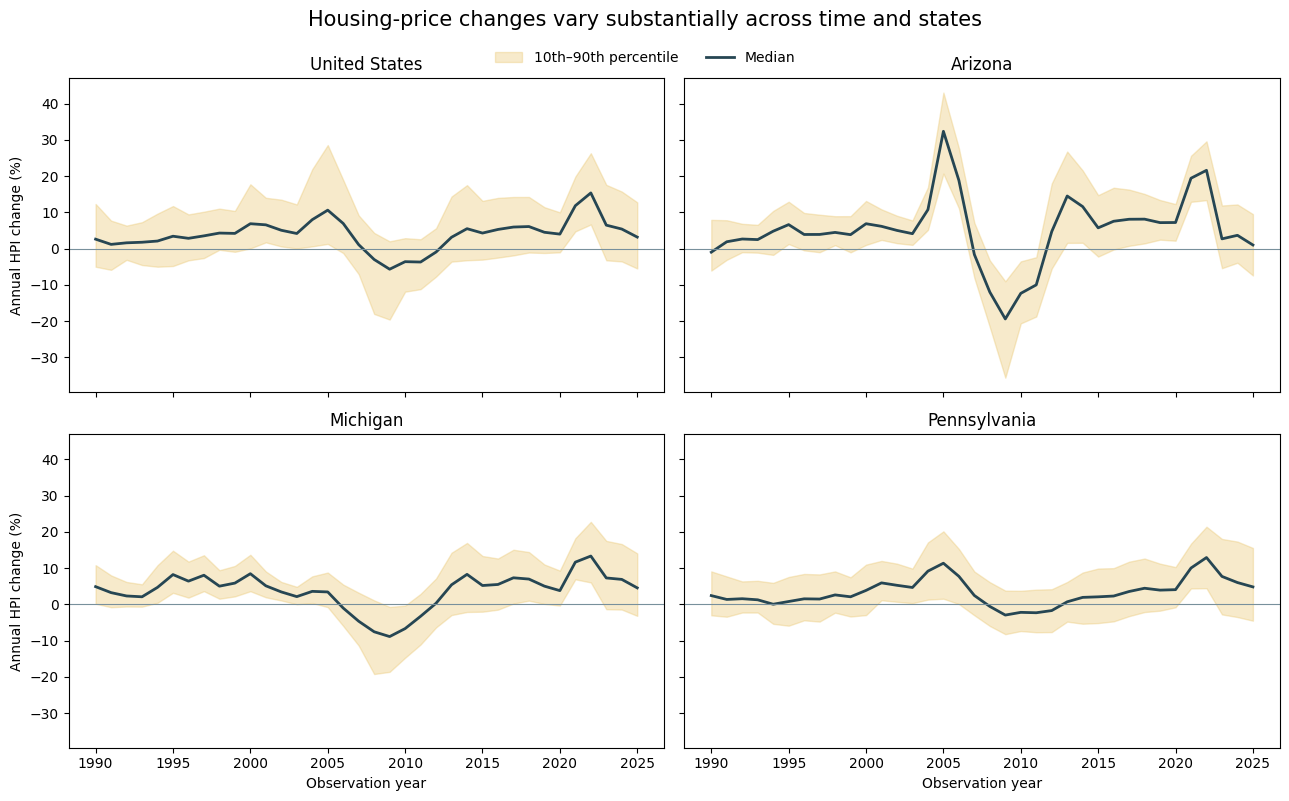

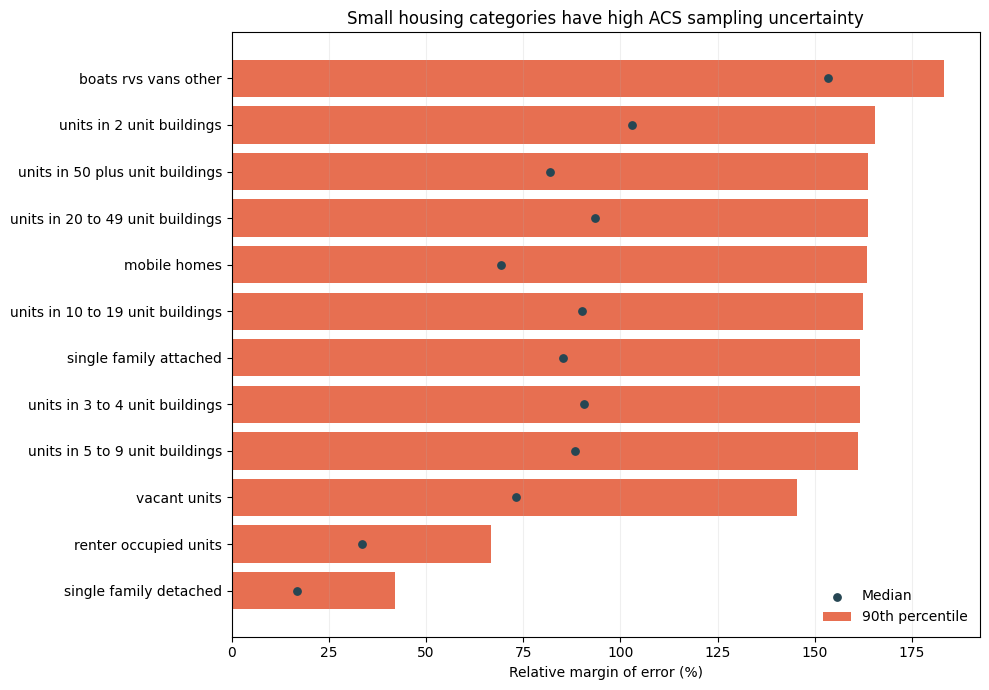

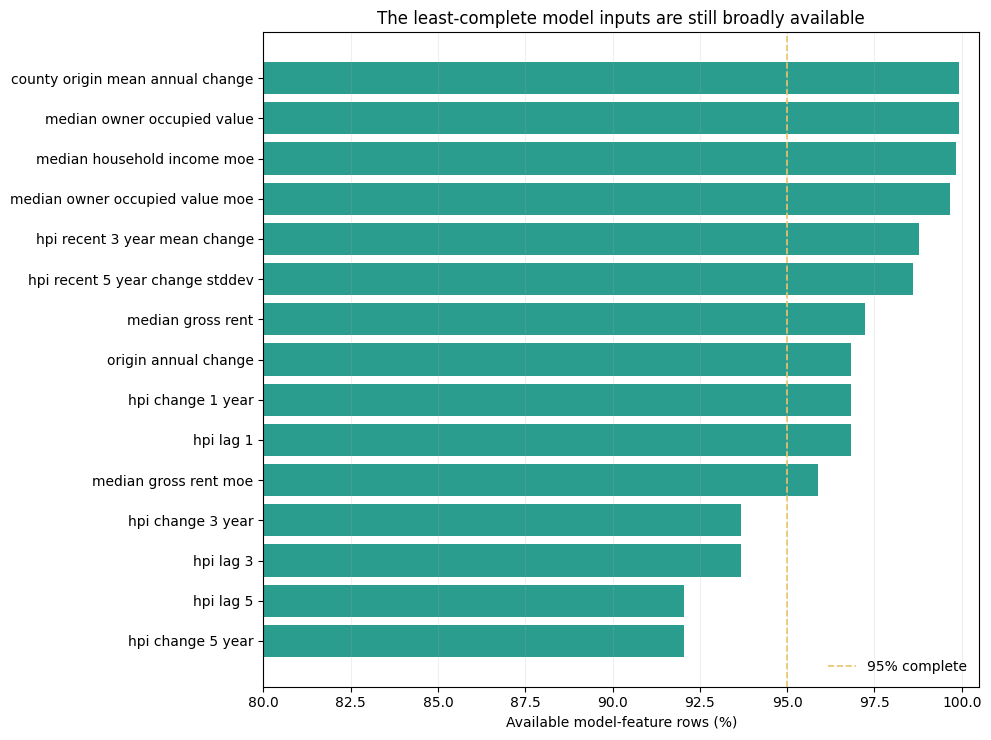

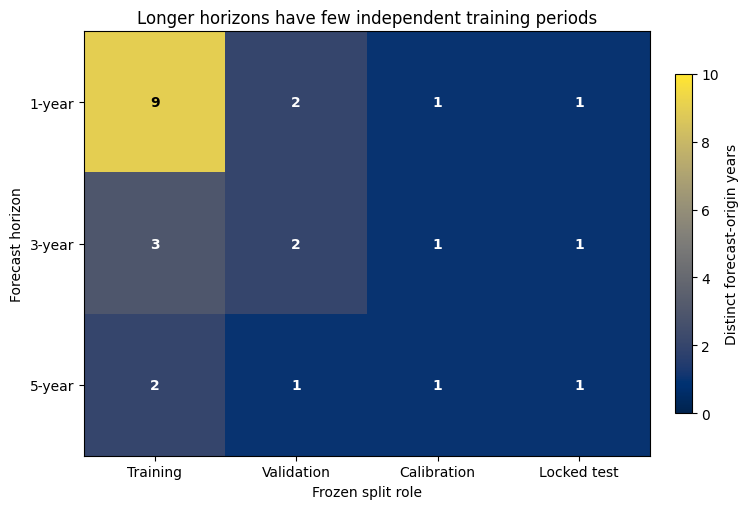

EDA source build IDs: {'visual_eda': '20261107T231242972903Z', 'acs_readiness': '20261107T231059124504Z', 'model_readiness': '20261107T185721624743Z'}
Saved six published Databricks EDA figures under c:\Users\Braeden\Documents\Hw\Capstone\neighborhood-digital-twin\reports\generated\meeting_forecast_demo\local_subset_figures


In [12]:
def read_eda_csv(filename: str) -> list[dict[str, str]]:
    path = EDA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing EDA aggregate {path}; run the refresh cell above.")
    with path.open(encoding="utf-8-sig", newline="") as handle:
        return list(csv.DictReader(handle))

def number(value: str) -> float:
    return float(value) if value not in (None, "") else math.nan

def save_eda_figure(figure: Any, filename: str) -> None:
    figure.tight_layout()
    figure.savefig(figure_dir / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)

eda_builds = {}
housing = [row for row in read_eda_csv("eda_02_housing_coverage.csv") if int(row["housing_composition_band_order"]) <= 5]
cohort = read_eda_csv("eda_03_cohort_comparison.csv")
temporal = [row for row in read_eda_csv("eda_04_hpi_temporal.csv") if int(row["observation_year"]) >= 1990]
uncertainty = read_eda_csv("eda_05_acs_quality.csv")
completeness_rows = read_eda_csv("eda_07_feature_completeness.csv")
split_rows = read_eda_csv("eda_08_split_origins.csv")

# Figure 2: current-ACS tracts with housing composition data.
x = list(range(len(housing)))
width = 0.36
figure, axis = plt.subplots(figsize=(11, 6))
axis.bar([value - width / 2 for value in x], [100 * number(row["fhfa_history_share"]) for row in housing], width, label="Any FHFA history", color="#2A9D8F")
axis.bar([value + width / 2 for value in x], [100 * number(row["forecast_candidate_share"]) for row in housing], width, label="Current forecast candidate", color="#E76F51")
axis.set_xticks(x, [row["housing_composition_band"] for row in housing], rotation=18, ha="right")
axis.set_ylabel("Share of current-ACS tracts (%)")
axis.set_ylim(0, 100)
axis.set_title("FHFA and forecast coverage rise with single-family housing share")
axis.legend(frameon=False, ncol=2, loc="upper left")
figure.subplots_adjust(bottom=0.28)
save_eda_figure(figure, "eda_02_housing_composition_coverage.png")
eda_builds["visual_eda"] = housing[0]["visual_eda_build_id"]

# Figure 3: national forecast-candidate selection differences.
cohort.sort(key=lambda row: number(row["standardized_mean_difference"]))
cohort_labels = [row["feature_name"].replace("_estimate", "").replace("_", " ") for row in cohort]
cohort_values = [number(row["standardized_mean_difference"]) for row in cohort]
figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(cohort_labels, cohort_values, color=["#2A9D8F" if value >= 0 else "#D1495B" for value in cohort_values])
axis.axvline(0, color="#455A64", linewidth=1)
axis.axvline(-0.2, color="#B0BEC5", linewidth=0.8, linestyle="--")
axis.axvline(0.2, color="#B0BEC5", linewidth=0.8, linestyle="--")
axis.set_xlabel("Standardized mean difference: forecast candidates minus excluded tracts")
axis.set_title("Forecast availability is associated with observable community differences")
axis.grid(axis="x", alpha=0.2)
save_eda_figure(figure, "eda_03_forecast_included_excluded_comparison.png")

# Figure 4: published national and pilot-state annual HPI summaries.
scopes = [("US", "United States"), ("04", "Arizona"), ("26", "Michigan"), ("42", "Pennsylvania")]
figure, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for axis, (scope_code, scope_label) in zip(axes.ravel(), scopes, strict=True):
    subset = sorted((row for row in temporal if row["scope_code"] == scope_code), key=lambda row: int(row["observation_year"]))
    subset = [row for row in subset if all(not math.isnan(number(row[key])) for key in ("p10_annual_change_pct", "median_annual_change_pct", "p90_annual_change_pct"))]
    years = [int(row["observation_year"]) for row in subset]
    axis.fill_between(years, [number(row["p10_annual_change_pct"]) for row in subset], [number(row["p90_annual_change_pct"]) for row in subset], color="#E9C46A", alpha=0.35, label="10th–90th percentile")
    axis.plot(years, [number(row["median_annual_change_pct"]) for row in subset], color="#264653", linewidth=2, label="Median")
    axis.axhline(0, color="#78909C", linewidth=0.8)
    axis.set_title(scope_label)
for axis in axes[:, 0]:
    axis.set_ylabel("Annual HPI change (%)")
for axis in axes[-1, :]:
    axis.set_xlabel("Observation year")
handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(handles, labels, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 0.96))
figure.suptitle("Housing-price changes vary substantially across time and states", y=0.995, fontsize=15)
figure.tight_layout(rect=(0, 0.02, 1, 0.9))
save_eda_figure(figure, "eda_04_hpi_temporal_behavior.png")

# Figure 5: twelve ACS measures with highest relative-MOE p90.
uncertainty.sort(key=lambda row: number(row["p90_relative_margin_of_error"]))
uncertainty_labels = [row["measure_name"].replace("_", " ") for row in uncertainty]
figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(uncertainty_labels, [100 * number(row["p90_relative_margin_of_error"]) for row in uncertainty], color="#E76F51", label="90th percentile")
axis.scatter([100 * number(row["median_relative_margin_of_error"]) for row in uncertainty], uncertainty_labels, color="#264653", s=28, zorder=3, label="Median")
axis.set_xlabel("Relative margin of error (%)")
axis.set_title("Small housing categories have high ACS sampling uncertainty")
axis.legend(frameon=False, loc="lower right")
axis.grid(axis="x", alpha=0.2)
save_eda_figure(figure, "eda_05_acs_measurement_uncertainty.png")

# Figure 7: least-complete model-readiness features before imputation.
completeness_rows.sort(key=lambda row: number(row["non_null_rate"]))
feature_labels = [row["dimension_value"].replace("_estimate", "").replace("_pct", "").replace("_", " ") for row in completeness_rows]
figure, axis = plt.subplots(figsize=(10, 7.5))
axis.barh(feature_labels, [100 * number(row["non_null_rate"]) for row in completeness_rows], color="#2A9D8F")
axis.axvline(95, color="#E9C46A", linewidth=1.2, linestyle="--", label="95% complete")
axis.set_xlim(80, 100.5)
axis.set_xlabel("Available model-feature rows (%)")
axis.set_title("The least-complete model inputs are still broadly available")
axis.legend(frameon=False, loc="lower right")
axis.grid(axis="x", alpha=0.2)
save_eda_figure(figure, "eda_07_model_feature_completeness.png")

# Figure 8: distinct origin years by horizon and frozen split role.
horizon_order = [1, 3, 5]
role_order = ["training", "validation", "calibration", "locked_temporal_test"]
role_labels = ["Training", "Validation", "Calibration", "Locked test"]
origin_matrix = [[0 for _ in role_order] for _ in horizon_order]
for row in split_rows:
    horizon = int(row["horizon_years"])
    role = row["temporal_role"]
    if horizon in horizon_order and role in role_order:
        origin_matrix[horizon_order.index(horizon)][role_order.index(role)] = int(row["origin_year_count"])
figure, axis = plt.subplots(figsize=(9, 5.2))
image = axis.imshow(origin_matrix, cmap="cividis", vmin=0, vmax=max(10, max(max(values) for values in origin_matrix)))
for row_index, values in enumerate(origin_matrix):
    for column_index, value in enumerate(values):
        axis.text(column_index, row_index, str(value), ha="center", va="center", color="white" if value < 5 else "black", fontweight="semibold")
axis.set_xticks(range(len(role_labels)), role_labels)
axis.set_yticks(range(len(horizon_order)), [f"{horizon}-year" for horizon in horizon_order])
axis.set_title("Longer horizons have few independent training periods")
axis.set_xlabel("Frozen split role")
axis.set_ylabel("Forecast horizon")
colorbar = figure.colorbar(image, ax=axis, shrink=0.8, pad=0.03)
colorbar.set_label("Distinct forecast-origin years")
save_eda_figure(figure, "eda_08_model_split_origin_years.png")

eda_builds["acs_readiness"] = uncertainty[0]["readiness_build_id"]
eda_builds["model_readiness"] = completeness_rows[0]["model_readiness_build_id"]
print(f"EDA source build IDs: {eda_builds}")
print(f"Saved six published Databricks EDA figures under {figure_dir}")